# Hybrid LSTM + ARIMA for volatility forecasting

`Hybrid_Model.ipynb` showed that, once data leakage is removed, no model beats the naive forecast
("tomorrow's price = today's price") on daily stock prices. Price direction is close to a random walk.

**Volatility is different.** How *much* a price moves, regardless of direction, clusters in time: calm days follow
calm days and turbulent days follow turbulent days. This notebook applies the **same hybrid design** to forecast
tomorrow's volatility for the same nine assets, with the same leak-free setup.

**Target.** Daily **Parkinson volatility**, which uses each day's high and low price:

$$\sigma^2_t = \frac{\left(\ln(H_t / L_t)\right)^2}{4 \ln 2}$$

It is much less noisy than a volatility estimate from one closing price change. We annualise it (× 252, square root,
in %) and model its **logarithm**, which is closer to normally distributed and keeps forecasts positive.

**Setup** (identical to `Hybrid_Model.ipynb`)

* Last 1,500 trading days up to 9 Oct 2026; chronological split 70% train / 15% validation / 15% test.
* Every forecast for day *t* uses only data up to day *t*-1.
* LSTM: 20-day window, 1 layer of 32 units, average of 3 random seeds, trained on the train block.
* **Hybrid** = LSTM + ARIMA fitted on the LSTM's residuals in the validation block.

**Models compared**

| Model | Forecast for tomorrow's log volatility |
|---|---|
| Naive | today's volatility |
| 22-day average | volatility averaged over the last month |
| HAR | linear regression on 1-day, 5-day and 22-day volatility; the standard benchmark in volatility research |
| ARIMA | `auto_arima` on log volatility |
| LSTM | neural network on the last 20 days |
| Hybrid | LSTM + ARIMA on LSTM residuals |

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"           # hide TensorFlow start-up messages
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from tensorflow import keras
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from scipy import stats

ASSETS = {
    "S&P 500":            "^GSPC",
    "NASDAQ Composite":   "^IXIC",
    "Zomato (Eternal)":   "ETERNAL.NS",
    "Adani Wilmar (AWL)": "AWL.NS",
    "IRCTC":              "IRCTC.NS",
    "SBI":                "SBIN.NS",
    "Tata Motors":        "TMPV.NS",
    "Jio Financial":      "JIOFIN.NS",
    "Gold (GOLDBEES)":    "GOLDBEES.NS",
}
END_DATE   = "2026-10-10"   # fixed end date for reproducible results
MAX_DAYS   = 1500           # last N trading days per asset
WINDOW     = 20             # LSTM look-back in trading days
TRAIN_FRAC = 0.70
VAL_FRAC   = 0.15
SEEDS      = [0, 1, 2]      # LSTM trained 3 times and averaged

# Chart colours (fixed order)
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6, "axes.titlesize": 10,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.frameon": False, "legend.fontsize": 8,
})

## 1. Data: daily volatility from high and low prices

In [2]:
def load_log_vol(ticker):
    df = yf.download(ticker, start="1990-01-01", end=END_DATE, auto_adjust=True, progress=False)
    df.columns = df.columns.get_level_values(0)                 # flatten yfinance's two-level column names
    df = df[["Open", "High", "Low", "Close"]].dropna().iloc[-MAX_DAYS:]
    hl = np.log(df["High"] / df["Low"])                         # daily range in log terms
    var = hl**2 / (4 * np.log(2))                               # Parkinson daily variance
    var = var.where(var > 0).ffill()                            # a few days have High = Low (data gaps): use the previous day
    return np.log(np.sqrt(var * 252) * 100).dropna()            # log of annualised volatility in %

log_vol = {name: load_log_vol(t) for name, t in ASSETS.items()}

summary = pd.DataFrame({
    "ticker": ASSETS.values(),
    "days": [len(s) for s in log_vol.values()],
    "from": [s.index[0].date() for s in log_vol.values()],
    "to": [s.index[-1].date() for s in log_vol.values()],
    "median vol %": [np.exp(s).median() for s in log_vol.values()],
}, index=ASSETS.keys())
summary.round(1)

,ticker,days,from,to,median vol %
S&P 500,^GSPC,1500,2020-10-20,2026-10-09,9.2
NASDAQ Composite,^IXIC,1500,2020-10-20,2026-10-09,12.2
Zomato (Eternal),ETERNAL.NS,1290,2021-07-23,2026-10-09,32.0
Adani Wilmar (AWL),AWL.NS,1154,2022-02-08,2026-10-09,26.3
IRCTC,IRCTC.NS,1500,2020-09-17,2026-10-09,20.4
SBI,SBIN.NS,1500,2020-09-17,2026-10-09,18.1
Tata Motors,TMPV.NS,1500,2020-09-17,2026-10-09,22.5
Jio Financial,JIOFIN.NS,775,2023-08-21,2026-10-09,21.6
Gold (GOLDBEES),GOLDBEES.NS,1500,2020-09-16,2026-10-09,12.3


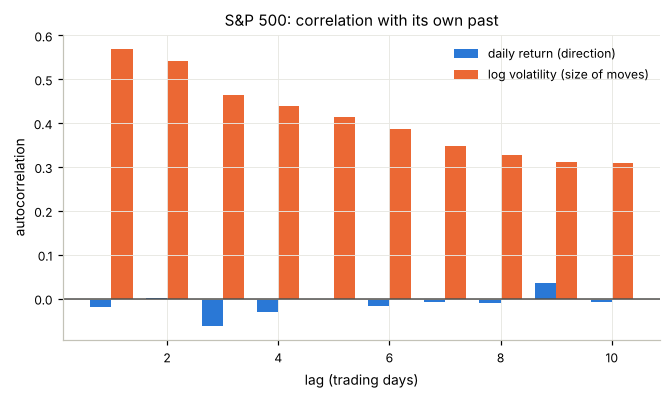

,1,2,3,4,5,6,7,8,9,10
daily return,-0.02,0.002,-0.062,-0.031,-0.002,-0.017,-0.008,-0.010,0.037,-0.007
log volatility,0.57,0.541,0.463,0.439,0.414,0.387,0.348,0.327,0.311,0.310


In [3]:
# Why volatility is forecastable and prices are not: correlation of today's value with the past
spx = yf.download("^GSPC", start="1990-01-01", end=END_DATE, auto_adjust=True, progress=False)["Close"].squeeze()
ret = np.log(spx).diff().dropna().iloc[-MAX_DAYS:]
lags = range(1, 11)
ac = pd.DataFrame({"daily return": [ret.autocorr(l) for l in lags],
                   "log volatility": [log_vol["S&P 500"].autocorr(l) for l in lags]}, index=lags)

fig, ax = plt.subplots(figsize=(7, 3.6))
w = 0.38
ax.bar(np.array(lags) - w/2, ac["daily return"], width=w, color=BLUE, label="daily return (direction)")
ax.bar(np.array(lags) + w/2, ac["log volatility"], width=w, color=ORANGE, label="log volatility (size of moves)")
ax.axhline(0, color=GRAY, linewidth=1)
ax.set(xlabel="lag (trading days)", ylabel="autocorrelation", title="S&P 500: correlation with its own past")
ax.legend()
plt.show()
ac.round(3).T

Daily returns have almost no memory, which is why price forecasts could not beat the naive model.
Volatility is strongly correlated with its own past for many days, so there is something for a model to learn.

## 2. Models

In [4]:
def split_points(n):
    a = int(TRAIN_FRAC * n)            # first validation position
    b = a + int(VAL_FRAC * n)          # first test position
    return a, b


def fixed_arima(y_fit, y_all, **auto_kw):
    # Choose the order with auto_arima on y_fit, estimate parameters on y_fit only, then run the same fitted model
    # over y_all. Returns one-step-ahead predictions: the value for position j uses only positions before j.
    sel = auto_arima(y_fit, seasonal=False, stepwise=True, suppress_warnings=True, error_action="ignore",
                     max_p=5, max_q=5, **auto_kw)
    order = sel.order
    trend = {0: "c", 1: "t"}.get(order[1], "n") if sel.with_intercept else "n"
    res = ARIMA(y_fit, order=order, trend=trend).fit()
    return np.asarray(res.apply(y_all).get_prediction().predicted_mean), order


def lstm_forecast(y, a, seed):
    # Train on targets before position a; return a forecast for every position j >= WINDOW (NaN before)
    keras.utils.set_random_seed(seed)
    scaler = StandardScaler().fit(y[:a].reshape(-1, 1))                 # train block only
    z = scaler.transform(y.reshape(-1, 1)).ravel()
    js = np.arange(WINDOW, len(y))
    X = np.stack([z[j - WINDOW:j] for j in js])[..., None]             # the 20 days BEFORE day j
    is_train = js < a

    model = keras.Sequential([keras.layers.Input((WINDOW, 1)), keras.layers.LSTM(32),
                              keras.layers.Dropout(0.2), keras.layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    model.fit(X[is_train], z[js][is_train], epochs=100, batch_size=32, verbose=0,
              validation_split=0.15,                                   # last 15% of the train block
              callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])
    out = np.full(len(y), np.nan)
    out[js] = scaler.inverse_transform(model.predict(X, verbose=0)).ravel()
    return out


def run_asset(s):
    y = s.values
    n = len(y)
    a, b = split_points(n)
    test = np.arange(b, n)
    prev = np.r_[np.nan, y[:-1]]                                         # yesterday's value
    var = np.exp(2 * y)                                                  # average on the variance scale
    past_avg = lambda k: np.r_[np.nan, np.log(np.sqrt(pd.Series(var).rolling(k).mean().values))[:-1]]

    f = {"Naive": prev, "22-day average": past_avg(22)}

    # HAR: linear regression on yesterday, last-week and last-month volatility, fitted on the train block
    H = np.column_stack([prev, past_avg(5), past_avg(22)])
    ok = ~np.isnan(H).any(axis=1)
    fit_rows = np.where(ok & (np.arange(n) < a))[0]
    har = LinearRegression().fit(H[fit_rows], y[fit_rows])
    f["HAR"] = np.full(n, np.nan)
    f["HAR"][ok] = har.predict(H[ok])

    f["ARIMA"], arima_order = fixed_arima(y[:a], y)
    f["LSTM"] = np.mean([lstm_forecast(y, a, s_) for s_ in SEEDS], axis=0)

    # Hybrid: ARIMA fitted on the LSTM's residuals in the validation block (out-of-sample for the LSTM)
    resid = y - f["LSTM"]
    resid_hat, resid_order = fixed_arima(resid[a:b], resid[a:], d=0)
    f["Hybrid"] = f["LSTM"].copy()
    f["Hybrid"][a:] += resid_hat

    return dict(dates=s.index[test], y=y[test], f={k: v[test] for k, v in f.items()},
                arima_order=arima_order, resid_order=resid_order,
                n_test=len(test), test_from=s.index[b].date())

## 3. Run on every asset

In [5]:
results = {}
for name, s in log_vol.items():
    results[name] = run_asset(s)
    o = results[name]
    print(f"{name:20s} ARIMA{o['arima_order']}  residual ARIMA{o['resid_order']}  "
          f"test: {o['n_test']} days from {o['test_from']}")

S&P 500              ARIMA(1, 1, 2)  residual ARIMA(2, 0, 0)  test: 225 days from 2025-11-17


NASDAQ Composite     ARIMA(2, 1, 2)  residual ARIMA(2, 0, 0)  test: 225 days from 2025-11-17


Zomato (Eternal)     ARIMA(2, 1, 1)  residual ARIMA(1, 0, 1)  test: 195 days from 2025-12-26


Adani Wilmar (AWL)   ARIMA(1, 1, 2)  residual ARIMA(0, 0, 0)  test: 174 days from 2026-01-27


IRCTC                ARIMA(2, 1, 1)  residual ARIMA(0, 0, 0)  test: 225 days from 2025-11-13


SBI                  ARIMA(2, 1, 3)  residual ARIMA(0, 0, 0)  test: 225 days from 2025-11-13


Tata Motors          ARIMA(1, 1, 2)  residual ARIMA(2, 0, 3)  test: 225 days from 2025-11-13


Jio Financial        ARIMA(1, 1, 1)  residual ARIMA(1, 0, 1)  test: 117 days from 2026-04-23


Gold (GOLDBEES)      ARIMA(1, 1, 2)  residual ARIMA(2, 0, 2)  test: 225 days from 2025-11-13


## 4. Evaluation

Errors are measured on **log volatility** in the test period. A log error of 0.10 means the forecast was about 10% too high or too low.

* **RMSE vs naive**: model RMSE ÷ naive RMSE. 0.80 means 20% lower error than "tomorrow = today".
* **Diebold-Mariano test**: is the difference in squared errors between two models statistically significant? p < 0.05 means very unlikely to be luck.

In [6]:
MODELS = ["Naive", "22-day average", "HAR", "ARIMA", "LSTM", "Hybrid"]

def dm_pvalue(e1, e2):
    d = e1**2 - e2**2
    if np.allclose(d, 0):
        return np.nan                                            # identical forecasts
    n = len(d)
    dm = d.mean() / np.sqrt(d.var(ddof=1) / n) * np.sqrt((n - 1) / n)
    return 2 * stats.t.sf(abs(dm), df=n - 1)

rows = []
for name, o in results.items():
    e = {m: o["y"] - o["f"][m] for m in MODELS}
    rmse_naive = np.sqrt(np.mean(e["Naive"]**2))
    for m in MODELS:
        rows.append({"asset": name, "model": m,
                     "RMSE (log vol)": np.sqrt(np.mean(e[m]**2)),
                     "MAE (log vol)": np.mean(np.abs(e[m])),
                     "RMSE vs naive": np.sqrt(np.mean(e[m]**2)) / rmse_naive})
metrics = pd.DataFrame(rows)
metrics.to_csv("results_volatility.csv", index=False)

ratio = metrics.pivot(index="asset", columns="model", values="RMSE vs naive").loc[list(ASSETS), MODELS]
ratio.loc["Average"] = ratio.mean()
ratio.round(3)

model,Naive,22-day average,HAR,ARIMA,LSTM,Hybrid
asset,,,,,,
S&P 500,1.0,0.990,0.820,0.802,0.803,0.808
NASDAQ Composite,1.0,0.966,0.814,0.799,0.807,0.803
Zomato (Eternal),1.0,0.900,0.819,0.814,0.862,0.801
Adani Wilmar (AWL),1.0,0.878,0.797,0.804,0.792,0.809
IRCTC,1.0,0.852,0.806,0.809,0.799,0.796
SBI,1.0,0.891,0.796,0.801,0.798,0.797
Tata Motors,1.0,0.861,0.788,0.788,0.784,0.826
Jio Financial,1.0,0.848,0.771,0.780,0.800,0.785
Gold (GOLDBEES),1.0,1.230,0.865,0.878,0.891,0.884


In [7]:
# Pairwise tests for the hybrid
def compare(name, other):
    o = results[name]
    e_h, e_o = o["y"] - o["f"]["Hybrid"], o["y"] - o["f"][other]
    better = np.mean(e_h**2) < np.mean(e_o**2)
    return ("lower" if better else "higher"), dm_pvalue(e_h, e_o)

tests = []
for name in ASSETS:
    row = {"asset": name}
    for other in ["Naive", "22-day average", "LSTM", "HAR"]:
        v, p = compare(name, other)
        row[f"Hybrid vs {other}"] = v
        row[f"p ({other})"] = p
    tests.append(row)
tests = pd.DataFrame(tests).set_index("asset")
tests.round(3)

,Hybrid vs Naive,p (Naive),Hybrid vs 22-day average,p (22-day average),Hybrid vs LSTM,p (LSTM),Hybrid vs HAR,p (HAR)
asset,,,,,,,,
S&P 500,lower,0.000,lower,0.000,higher,0.635,lower,0.329
NASDAQ Composite,lower,0.000,lower,0.000,lower,0.710,lower,0.408
Zomato (Eternal),lower,0.000,lower,0.001,lower,0.016,lower,0.333
Adani Wilmar (AWL),lower,0.000,lower,0.096,higher,0.274,higher,0.399
IRCTC,lower,0.000,lower,0.051,lower,0.677,lower,0.413
SBI,lower,0.000,lower,0.001,lower,0.967,higher,0.888
Tata Motors,lower,0.000,lower,0.277,higher,0.023,higher,0.029
Jio Financial,lower,0.000,lower,0.089,lower,0.563,higher,0.314
Gold (GOLDBEES),lower,0.022,lower,0.000,lower,0.591,higher,0.320


In [8]:
# How many assets does the hybrid beat each comparison model on, and how many of those wins are significant?
summ = []
for other in ["Naive", "22-day average", "LSTM", "HAR"]:
    lower = tests[f"Hybrid vs {other}"] == "lower"
    sig = tests[f"p ({other})"] < 0.05
    summ.append({"compared with": other,
                 "hybrid lower error": int(lower.sum()),
                 "  ...significant (p<0.05)": int((lower & sig).sum()),
                 "hybrid higher error": int((~lower).sum()),
                 "  ...significant (p<0.05) ": int((~lower & sig).sum())})
pd.DataFrame(summ).set_index("compared with")

,hybrid lower error,...significant (p<0.05),hybrid higher error,...significant (p<0.05)
compared with,,,,
Naive,9,9,0,0
22-day average,9,5,0,0
LSTM,6,1,3,1
HAR,4,0,5,1


## 5. Charts

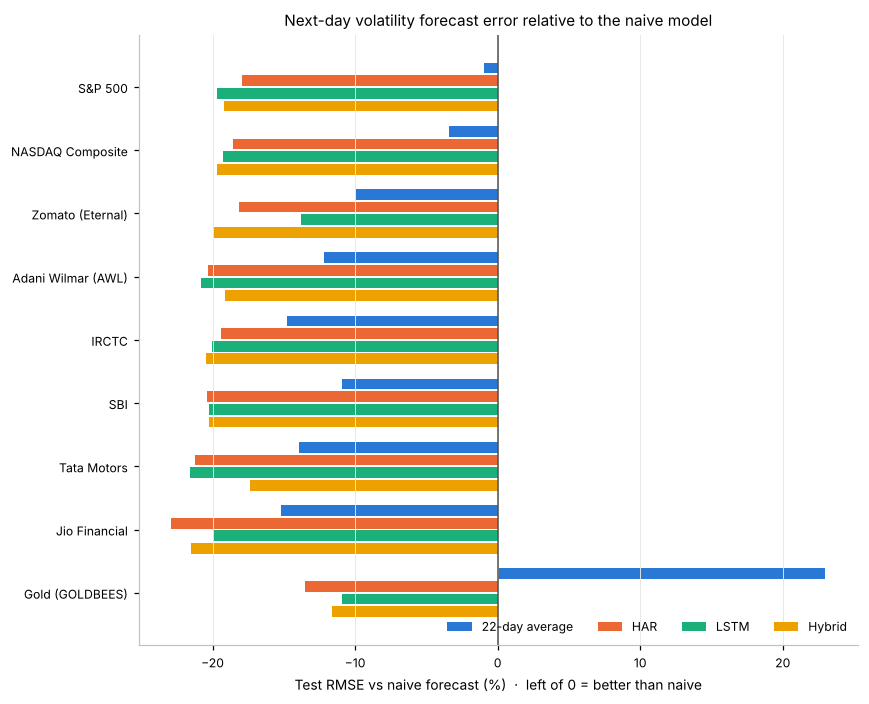

In [9]:
# Error relative to the naive forecast, per asset (left of 0 = better than naive)
show = [("22-day average", BLUE), ("HAR", ORANGE), ("LSTM", AQUA), ("Hybrid", YELLOW)]
names = list(ASSETS)[::-1]
y = np.arange(len(names))
h = 0.2
fig, ax = plt.subplots(figsize=(8, 6.5))
for k, (m, c) in enumerate(show):
    vals = [(ratio.loc[n, m] - 1) * 100 for n in names]
    ax.barh(y + (1.5 - k) * h, vals, height=h * 0.85, color=c, label=m)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_yticks(y, names)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Test RMSE vs naive forecast (%)  ·  left of 0 = better than naive")
ax.set_title("Next-day volatility forecast error relative to the naive model")
ax.legend(loc="lower right", ncol=4)
plt.tight_layout()
plt.savefig("vol_vs_naive.png", bbox_inches="tight")
plt.show()

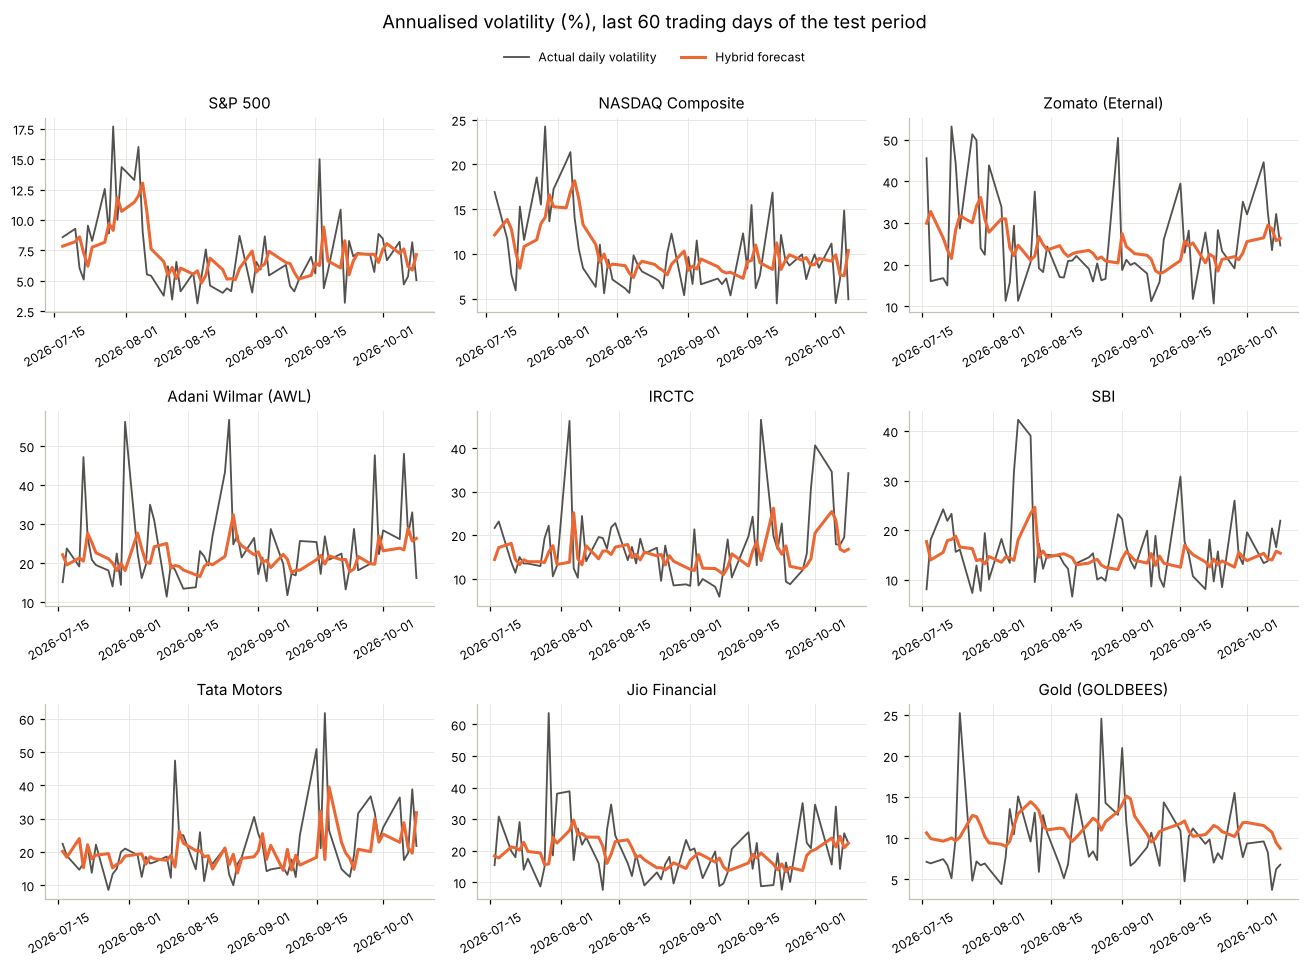

In [10]:
# Last 60 test days: actual volatility vs hybrid forecast (in %, not log)
fig, axes = plt.subplots(3, 3, figsize=(12, 8.5))
for ax, (name, o) in zip(axes.ravel(), results.items()):
    s = slice(-60, None)
    ax.plot(o["dates"][s], np.exp(o["y"][s]), color=GRAY, linewidth=1.2, label="Actual daily volatility")
    ax.plot(o["dates"][s], np.exp(o["f"]["Hybrid"][s]), color=ORANGE, linewidth=2, label="Hybrid forecast")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Annualised volatility (%), last 60 trading days of the test period", y=1.03)
plt.tight_layout()
plt.savefig("vol_forecasts_last60.png", bbox_inches="tight")
plt.show()

## 6. Findings

**1. Volatility is forecastable, and the hybrid forecasts it well.** Unlike prices, every model beats the naive
forecast. The hybrid has **12% to 22% lower error than naive on all nine assets (18.8% on average), and every
difference is statistically significant** (p < 0.05). It also beats the 22-day average on all nine assets
(significant on five).

**2. The hybrid improves on the LSTM alone on 6 of 9 assets**, though on average only slightly (RMSE ratio 0.812 vs 0.815).

* **Zomato** shows the design working as intended. The LSTM alone was the weakest model there (0.862). The residual
  ARIMA(1,0,1) found persistence the LSTM had missed and cut the error by 7% (p = 0.016).
* On **Adani Wilmar, IRCTC and SBI**, the residual ARIMA chose order (0,0,0): the LSTM's errors were noise, and the
  hybrid only shifted forecasts by a constant. Differences there are not significant. This is the diagnostic role of
  the hybrid: it tells you whether the neural network left anything on the table.
* On **Tata Motors** the hybrid was 5% worse than the LSTM (p = 0.023). The residual ARIMA(2,0,3) learned patterns
  from a validation period that includes the October 2025 demerger, and they did not carry into the test period.
  A second model on top can overfit; that is the cost of the design.

**3. The hybrid matches, but does not beat, the standard econometric benchmark.** Against HAR it has lower error on
4 assets and higher on 5, with only one significant difference (Tata Motors). HAR and ARIMA average 0.808, the hybrid
0.812. For a single, short volatility series, a simple linear model is as good as a neural network.

**4. Same pipeline, different target.** On prices, no model beat the naive forecast. On volatility, every model beats
it by about 20%. The modelling code barely changed; the difference was choosing a target that actually contains
predictable structure.